In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


# ============================================================
# Paths
# ============================================================

DATA_FILE = "Dataset_14_features.xlsx"
MODEL_FILE = "NGB_14_features_model.pkl"

OUTPUT_DIR = "ArticleFigures"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# Load dataset
# ============================================================

df = pd.read_excel(DATA_FILE)

print("Dataset shape:", df.shape)

Dataset shape: (141, 19)


In [2]:
# ============================================================
# 14 FEATURES
# ============================================================

FEATURES = [
    "Cross/C ratio",
    "D/C ratio",
    "Chitosan_MW",
    "Chitosan_DDA",
    "DS",
    "Modifier_LogP",
    "Modifier_pka",
    "Cross_MW",
    "Cross_pka",
    "Drug_MW",
    "Drug_pka",
    "PS",
    "NumHDonors",
    "MolLogP"
]

X = df[FEATURES].astype(float).copy()
y = df["DL"].astype(float).copy()

print("Number of features:", len(FEATURES))
print(FEATURES)

Number of features: 14
['Cross/C ratio', 'D/C ratio', 'Chitosan_MW', 'Chitosan_DDA', 'DS', 'Modifier_LogP', 'Modifier_pka', 'Cross_MW', 'Cross_pka', 'Drug_MW', 'Drug_pka', 'PS', 'NumHDonors', 'MolLogP']


In [4]:
# ============================================================
# LOAD NGB MODEL
# ============================================================

with open(MODEL_FILE, "rb") as file:
    NGB_model = pickle.load(file)

print("Model type:")
print(type(NGB_model))


# ============================================================
# STANDARDIZATION
# ============================================================

stdScale = StandardScaler()

X_scale = stdScale.fit_transform(X)

X_scale_df = pd.DataFrame(
    X_scale,
    columns=FEATURES,
    index=X.index
)

Model type:
<class 'ngboost.api.NGBRegressor'>


In [5]:
# ============================================================
# PREDICTED DL
# ============================================================

predicted_DL = np.asarray(
    NGB_model.predict(X_scale_df),
    dtype=float
)

print("Predicted DL range:")
print(
    predicted_DL.min(),
    "to",
    predicted_DL.max()
)

Predicted DL range:
0.43000001186562553 to 87.45000000811675


In [6]:
# ============================================================
# SHAP EXPLAINER
# ============================================================

print("Creating SHAP explainer...")

background_size = min(
    50,
    len(X_scale_df)
)

background = X_scale_df.sample(
    n=background_size,
    random_state=42
)

explainer = shap.PermutationExplainer(
    NGB_model.predict,
    background
)

print("Calculating SHAP values...")

shap_explanation = explainer(
    X_scale_df
)

shap_values = shap_explanation.values

print(
    "SHAP matrix shape:",
    shap_values.shape
)

Creating SHAP explainer...
Calculating SHAP values...


PermutationExplainer explainer: 142it [01:03,  2.01it/s]                         

SHAP matrix shape: (141, 14)


In [7]:
# ============================================================
# PCA
# ============================================================

n_components_pca = min(
    len(FEATURES),
    X_scale_df.shape[0]
)

pca = PCA(
    n_components=n_components_pca,
    random_state=42
)

shap_pca = pca.fit_transform(
    shap_values
)

print(
    "PCA shape:",
    shap_pca.shape
)

print(
    "Explained variance:",
    pca.explained_variance_ratio_.sum()
)


# ============================================================
# t-SNE
# ============================================================

# With 141 observations, perplexity=30 .

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

shap_embedded = tsne.fit_transform(
    shap_pca
)

print(
    "t-SNE shape:",
    shap_embedded.shape
)

PCA shape: (141, 14)
Explained variance: 1.0000000000000004
t-SNE shape: (141, 2)


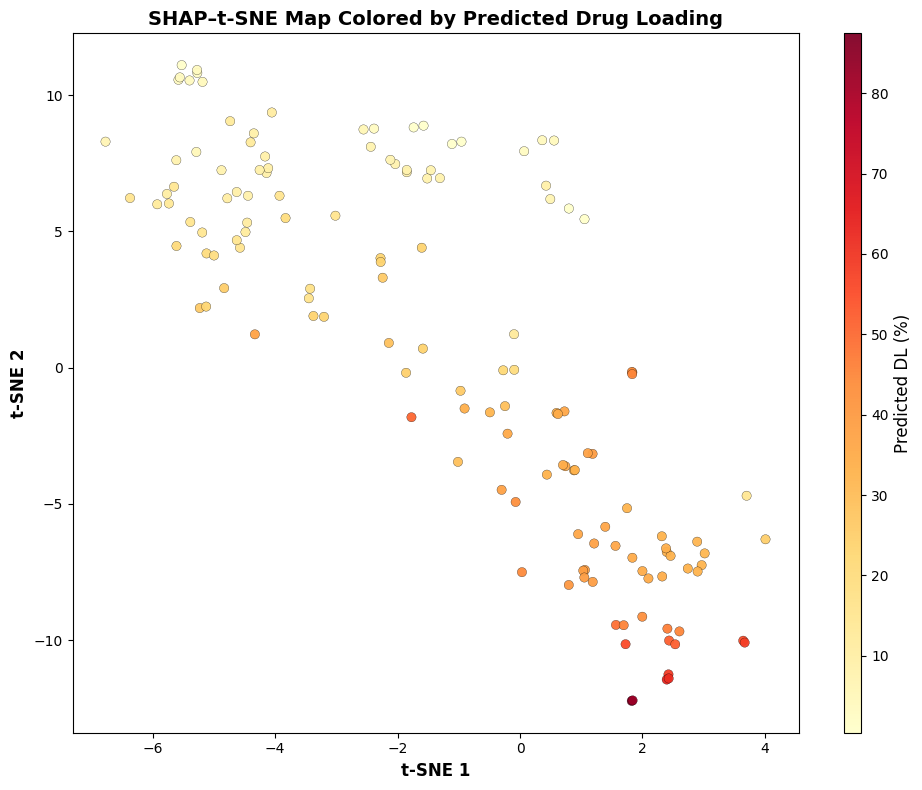

In [8]:
# ============================================================
# t-SNE COLORED BY PREDICTED DL
# ============================================================

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    shap_embedded[:, 0],
    shap_embedded[:, 1],
    c=predicted_DL,
    linewidths=0.2,
    alpha=0.95,
    edgecolors="black",
    cmap="YlOrRd",
    s=45
)

cbar = plt.colorbar(
    scatter,
    aspect=40,
    orientation="vertical"
)

cbar.set_label(
    "Predicted DL (%)",
    fontsize=12
)

plt.title(
    "SHAP–t-SNE Map Colored by Predicted Drug Loading",
    fontsize=14,
    color="black",
    weight="bold"
)

plt.xlabel(
    "t-SNE 1",
    fontsize=12,
    color="black",
    weight="bold"
)

plt.ylabel(
    "t-SNE 2",
    fontsize=12,
    color="black",
    weight="bold"
)

plt.tight_layout()


# ============================================================
# SAVE
# ============================================================

base = os.path.join(
    OUTPUT_DIR,
    "tSNE_Predicted_DL"
)

plt.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    base + ".jpg",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    base + ".jpeg",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    base + ".tiff",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    base + ".pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.show()
plt.close()

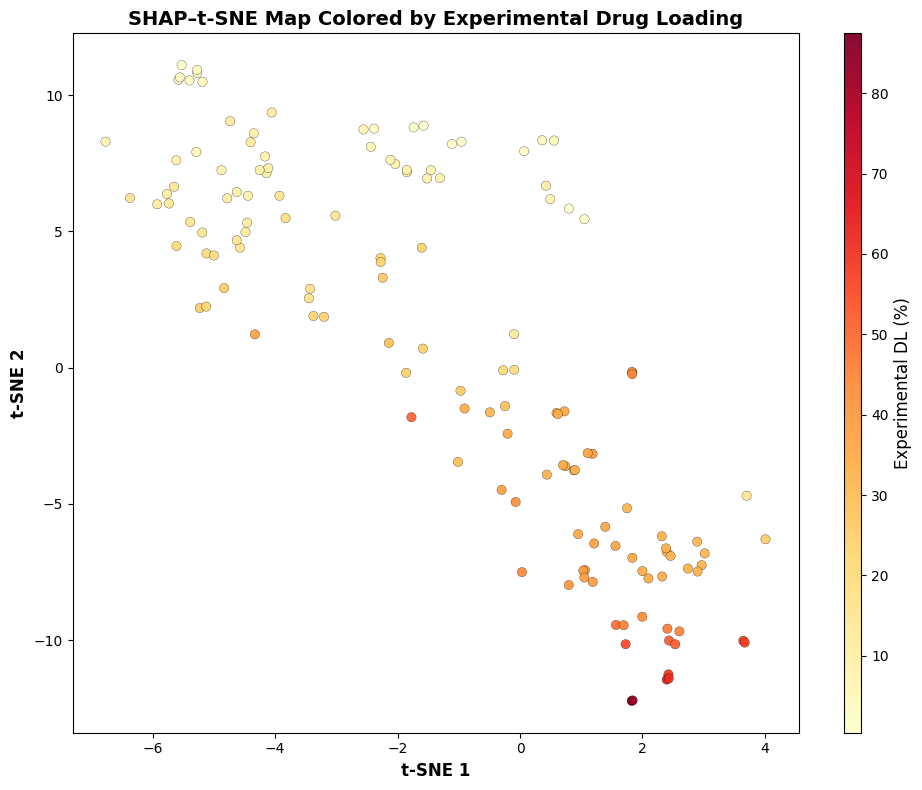

In [9]:
# ============================================================
# t-SNE COLORED BY EXPERIMENTAL DL
# ============================================================

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    shap_embedded[:, 0],
    shap_embedded[:, 1],
    c=y,
    linewidths=0.2,
    alpha=0.95,
    edgecolors="black",
    cmap="YlOrRd",
    s=45
)

cbar = plt.colorbar(
    scatter,
    aspect=40,
    orientation="vertical"
)

cbar.set_label(
    "Experimental DL (%)",
    fontsize=12
)

plt.title(
    "SHAP–t-SNE Map Colored by Experimental Drug Loading",
    fontsize=14,
    color="black",
    weight="bold"
)

plt.xlabel(
    "t-SNE 1",
    fontsize=12,
    color="black",
    weight="bold"
)

plt.ylabel(
    "t-SNE 2",
    fontsize=12,
    color="black",
    weight="bold"
)

plt.tight_layout()


base = os.path.join(
    OUTPUT_DIR,
    "tSNE_Experimental_DL"
)

plt.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    base + ".jpg",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    base + ".jpeg",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    base + ".tiff",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    base + ".pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.show()
plt.close()

In [10]:
# ============================================================
# DEFINE HIGH- AND LOW-DL FORMULATIONS
# ============================================================

high_threshold = np.percentile(
    predicted_DL,
    80
)

low_threshold = np.percentile(
    predicted_DL,
    20
)

high_DL_mask = (
    predicted_DL >= high_threshold
)

low_DL_mask = (
    predicted_DL <= low_threshold
)

print(
    f"High-DL threshold (80th percentile): "
    f"{high_threshold:.2f}%"
)

print(
    f"Low-DL threshold (20th percentile): "
    f"{low_threshold:.2f}%"
)

print(
    "High-DL formulations:",
    high_DL_mask.sum()
)

print(
    "Low-DL formulations:",
    low_DL_mask.sum()
)

High-DL threshold (80th percentile): 38.00%
Low-DL threshold (20th percentile): 8.04%
High-DL formulations: 29
Low-DL formulations: 29


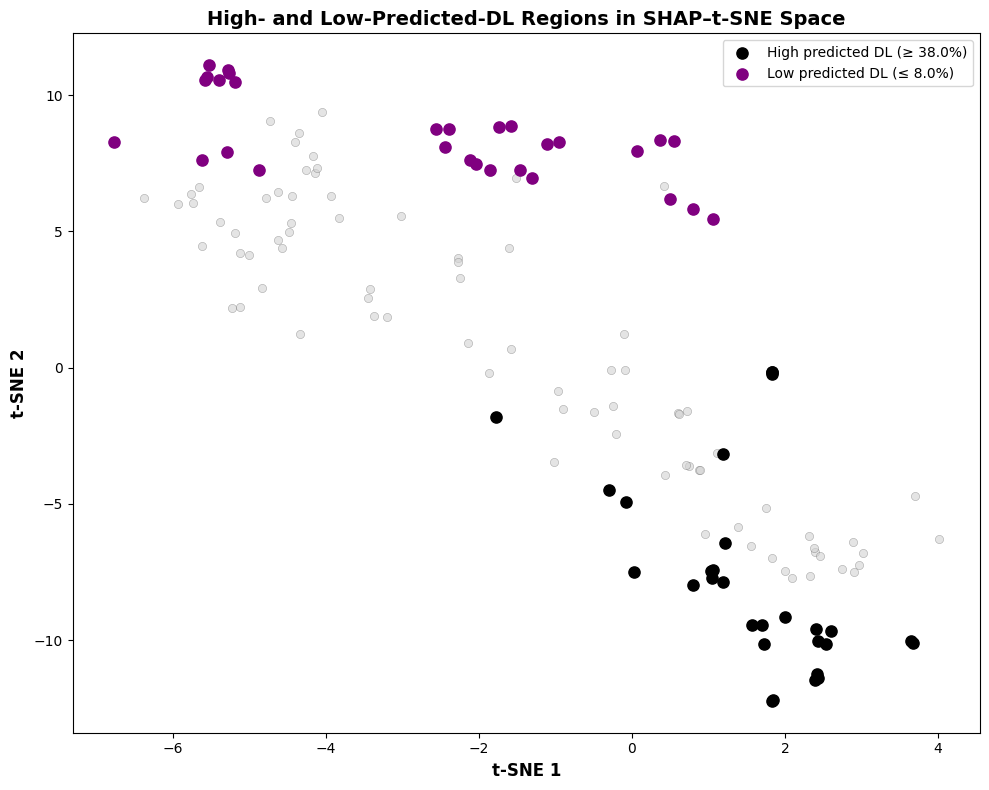

In [11]:
# ============================================================
# HIGH- AND LOW-DL REGIONS
# ============================================================

plt.figure(figsize=(10, 8))

# All points
plt.scatter(
    shap_embedded[:, 0],
    shap_embedded[:, 1],
    c="lightgray",
    s=35,
    alpha=0.6,
    edgecolors="black",
    linewidths=0.2
)

# High-DL formulations
plt.scatter(
    shap_embedded[high_DL_mask, 0],
    shap_embedded[high_DL_mask, 1],
    c="black",
    s=65,
    label=(
        f"High predicted DL "
        f"(≥ {high_threshold:.1f}%)"
    )
)

# Low-DL formulations
plt.scatter(
    shap_embedded[low_DL_mask, 0],
    shap_embedded[low_DL_mask, 1],
    c="purple",
    s=65,
    label=(
        f"Low predicted DL "
        f"(≤ {low_threshold:.1f}%)"
    )
)

plt.xlabel(
    "t-SNE 1",
    fontsize=12,
    weight="bold"
)

plt.ylabel(
    "t-SNE 2",
    fontsize=12,
    weight="bold"
)

plt.title(
    "High- and Low-Predicted-DL Regions in SHAP–t-SNE Space",
    fontsize=14,
    weight="bold"
)

plt.legend()

plt.tight_layout()


base = os.path.join(
    OUTPUT_DIR,
    "tSNE_High_Low_Predicted_DL"
)

plt.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    base + ".jpg",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    base + ".jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    base + ".tiff",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    base + ".pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [13]:
# ============================================================
# FEATURE-VALUE HEATMAPS
# ============================================================

for feature in FEATURES:

    feature_values = X[feature].values.astype(float)

    feature_min = feature_values.min()
    feature_max = feature_values.max()

    if feature_max == feature_min:

        norm_feature = np.zeros_like(
            feature_values
        )

    else:

        norm_feature = (
            (feature_values - feature_min) /
            (feature_max - feature_min)
        )


    plt.figure(figsize=(10, 8))

    scatter = plt.scatter(
        shap_embedded[:, 0],
        shap_embedded[:, 1],
        c=norm_feature,
        linewidths=0.2,
        alpha=0.95,
        edgecolors="black",
        cmap="YlOrRd",
        s=45
    )

    cbar = plt.colorbar(
        scatter,
        aspect=40,
        orientation="horizontal"
    )

    cbar.set_label(
        feature,
        fontsize=11
    )

    plt.title(
        f"SHAP–t-SNE Feature Map: {feature}",
        fontsize=12,
        color="black",
        weight="bold"
    )

    plt.xlabel(
        "t-SNE 1",
        fontsize=12,
        weight="bold"
    )

    plt.ylabel(
        "t-SNE 2",
        fontsize=12,
        weight="bold"
    )

    plt.tight_layout()


    # Safe filename
    safe_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
    )

    base = os.path.join(
        OUTPUT_DIR,
        f"tSNE_{safe_name}"
    )


    plt.savefig(
        base + ".png",
        dpi=600,
        bbox_inches="tight",
        transparent=True
    )

    plt.savefig(
        base + ".jpg",
        dpi=600,
        bbox_inches="tight",
        transparent=True
    )

    plt.savefig(
        base + ".jpeg",
        dpi=600,
        bbox_inches="tight",
        transparent=True
    )

    plt.savefig(
        base + ".tiff",
        dpi=600,
        bbox_inches="tight",
        transparent=True
    )

    plt.savefig(
        base + ".pdf",
        dpi=600,
        bbox_inches="tight",
        transparent=True
    )

    plt.close()

    print(
        f"Saved: {feature}"
    )

Saved: Cross/C ratio
Saved: D/C ratio
Saved: Chitosan_MW
Saved: Chitosan_DDA
Saved: DS
Saved: Modifier_LogP
Saved: Modifier_pka
Saved: Cross_MW
Saved: Cross_pka
Saved: Drug_MW
Saved: Drug_pka
Saved: PS
Saved: NumHDonors
Saved: MolLogP


In [14]:
# ============================================================
# SAVE EMBEDDING + DL VALUES
# ============================================================

embedding_df = pd.DataFrame({

    "tSNE_1": shap_embedded[:, 0],

    "tSNE_2": shap_embedded[:, 1],

    "Experimental_DL": y.values,

    "Predicted_DL": predicted_DL,

    "High_DL_region": high_DL_mask,

    "Low_DL_region": low_DL_mask,

    "Modification": df["Modification"].values,

    "Drug": df["Drug"].values,

    "Formulation_number":
        df["Formulation_number"].values
})

embedding_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_tSNE_14_features_data.xlsx"
    ),
    index=False
)

print(
    "t-SNE data saved."
)

t-SNE data saved.
